# Sponsor equity responses to project-loan signings: event study (Fig. 5)

Replication code for the equity-market event study in *Project financing in vanishing forests:
Do investors care about nature protection?*

## Design

- **Events.** Loan signing dates of project loans whose sponsors are listed firms headquartered in
  developed markets. Signings on a Saturday or Sunday are moved to the following Monday. Loans signed
  by the same sponsor on the same day form one event. 
- **Returns.** Daily simple returns, in per cent, computed from sponsor share prices.
- **Model.** Five-factor model with developed-market factors (market excess return, SMB, HML, RMW, CMA),
  estimated by OLS on each sponsor's excess returns over the estimation window. The expected return is
  the risk-free rate plus the estimated loadings multiplied by the factor returns; the estimated
  intercept is not included. Events with fewer than `MIN_EST_OBS` returns in the estimation window
  are dropped.
- **Event time.** Calendar days relative to signing (day 0). Estimation window: days -292 to -41.
  Event window: days -30 to +30.
- **CARs and CAARs.** CAR_i(t) sums abnormal returns on trading days from day -15 to day t.
  CAAR(t) is the mean of CAR_i(t) over events with a return on day t, so the number of events
  varies across days. 95% confidence intervals use the cross-sectional standard deviation and the
  t distribution.
- **Subsamples.** Projects within 10, 20, 30 and 40 km of the nearest protected area
  (`wdpa_Distance_km`); projects with non-burn forest loss within 10 km in the ten years after signing
  (`nonburn10km_10yr_post`) above the median or the 75th percentile; and projects within 10 km of a
  protected area with forest loss above the 75th percentile among projects within 10 km. Percentiles
  are taken across the project-loan pairs linked to an event. An event enters a subsample if any loan
  signed by that sponsor on that day meets the condition.

## Input files (in `DATA_DIR`)

| File | Content | Columns used |
|---|---|---|
| `MainReturnData.csv` | Daily share prices; one column per ISIN | first column: date (dd/mm/yyyy); ISIN columns: prices |
| `new_dates_colors_Oct2025 - LoanDate.csv` | Sponsor ISINs and loan signing dates | `ProjectID`, `ISIN`, `Date` (dd/mm/yyyy), `Group` (Dev / Emer) |
| `All Factors.csv` | Daily market and risk-free returns by market group | `Group`, `Date` (yyyymmdd), `market_return`, `risk_free_return` |
| `Developed_5_Factors_Daily_new.csv` | Daily developed-market factors, per cent | `Date` (yyyymmdd), `market_premium`, `SMB`, `HML`, `RMW`, `CMA`, `RF` |
| `sponsors id with loan dates_new_burn.csv` | Project-loan-sponsor characteristics | `ProjectID`, `ISIN`, `LoanSigningDate` (dd/mm/yyyy), `wdpa_Distance_km`, `nonburn10km_10yr_post` |

Data sources are listed in the paper's data availability statement (project and loan records from
SDC Platinum, share prices from LSEG Workspace, factors from Kenneth R. French's data library,
protected areas from the WDPA, forest loss from GLAD and MODIS).

## Outputs (in `OUT_DIR`)

- `figure5.png`, `figure5.pdf`: Fig. 5.
- `figure5_caar.csv`: N, CAAR, standard deviation and 95% confidence interval by sample and day.

Tested with Python 3.12, pandas 3.0, NumPy 2.5, SciPy 1.18 and Matplotlib 3.11. Run time is about 20 seconds.

In [10]:
import csv
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# The cross-section has 185 columns; pandas warns about fragmentation when columns are added.
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

# ---------------------------------------------------------------- files
DATA_DIR = Path(r"F:\Green")      # folder with the input files
OUT_DIR = DATA_DIR / "output"     # folder for the figure and table

RETURN_FILE = DATA_DIR / "MainReturnData.csv"
EVENT_FILE = DATA_DIR / "new_dates_colors_Oct2025 - LoanDate.csv"
MARKET_FILE = DATA_DIR / "All Factors.csv"
FACTOR_FILE = DATA_DIR / "Developed_5_Factors_Daily_new.csv"
CROSS_FILE = DATA_DIR / "sponsors id with loan dates_new_burn.csv"

# ---------------------------------------------------------------- event-study design (calendar days)
EST_WINDOW = (-292, -41)    # estimation window, inclusive
EVENT_WINDOW = (-30, 30)    # abnormal returns are computed over this window
CAR_START, CAR_END = -15, 15  # CARs are cumulated from CAR_START
PLOT_WINDOW = (-5, 5)

MIN_EST_OBS = 7             # six coefficients are estimated; events with fewer returns are dropped
INCLUDE_ALPHA = False       # expected return = RF + b'F (intercept not included)

DIST_VAR = "wdpa_Distance_km"
FOREST_VAR = "nonburn10km_10yr_post"
FACTORS = ["market_premium", "SMB", "HML", "RMW", "CMA"]

OUT_DIR.mkdir(parents=True, exist_ok=True)

In [11]:
# ---------------------------------------------------------------- helpers
def read_ddmmyyyy(s):
    return pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")


def read_yyyymmdd(s):
    return pd.to_datetime(s.astype("Int64").astype(str), format="%Y%m%d", errors="coerce")


def to_days(dates):
    """Datetime values -> integer day numbers."""
    return pd.DatetimeIndex(dates).values.astype("datetime64[D]").astype(np.int64)


def percentile(x, q):
    """Percentile from the inverse empirical distribution function, averaging at
    discontinuities (Hyndman and Fan, definition 2)."""
    x = pd.Series(x).dropna().to_numpy()
    return np.quantile(x, q, method="averaged_inverted_cdf")


def caar_table(df, window=PLOT_WINDOW):
    """N, CAAR, standard deviation and 95% t-interval of CARs by event day."""
    d = df[df["day"].between(*window)]
    g = d.groupby("day")["car"].agg(n="count", mean="mean", std="std")
    half = stats.t.ppf(0.975, g["n"] - 1) * g["std"] / np.sqrt(g["n"])
    g["lower"] = g["mean"] - half
    g["upper"] = g["mean"] + half
    return g.reset_index()

In [12]:
# ---------------------------------------------------------------- event dates
events_raw = pd.read_csv(EVENT_FILE, dtype={"ISIN": str, "Group": str})
events_raw["Date"] = read_ddmmyyyy(events_raw["Date"])
events_raw = (events_raw.sort_values(["ProjectID", "ISIN", "Date"], kind="stable")
                        .drop_duplicates(["ProjectID", "ISIN", "Date"]))

# Market group of each sponsor (Dev / Emer); sponsors without a group are treated as Dev.
isin_group = events_raw.groupby("ISIN")["Group"].first().fillna("Dev")
dev_isins = isin_group.index[isin_group.eq("Dev")]

# Signings on a Saturday or Sunday are moved to the following Monday.
events = events_raw[["ISIN", "Date"]].rename(columns={"Date": "event_date"}).dropna()
weekday = events["event_date"].dt.weekday
events.loc[weekday == 5, "event_date"] += pd.Timedelta(days=2)
events.loc[weekday == 6, "event_date"] += pd.Timedelta(days=1)

# One event per sponsor and signing date.
events = (events.drop_duplicates(["ISIN", "event_date"])
                .sort_values(["ISIN", "event_date"])
                .reset_index(drop=True))
print(f"Sponsor-signing events: {len(events):,} ({events['ISIN'].nunique():,} ISINs); "
      f"developed-market: {events['ISIN'].isin(dev_isins).sum():,}")

Sponsor-signing events: 2,631 (988 ISINs); developed-market: 2,035


In [13]:
# ---------------------------------------------------------------- daily returns and factors
# The header is read separately: where an ISIN heads more than one column, the last column is used.
with open(RETURN_FILE, newline="", encoding="utf-8-sig") as f:
    header = next(csv.reader(f))
col_pos = {name: i for i, name in enumerate(header)}
use_pos = [0] + sorted(col_pos[i] for i in dev_isins if i in col_pos)

prices = pd.read_csv(RETURN_FILE, header=None, skiprows=1, usecols=use_pos,
                     dtype=str, encoding="utf-8-sig")
prices.columns = [header[i] for i in use_pos]
prices = prices.rename(columns={header[0]: "Date"})
prices["Date"] = read_ddmmyyyy(prices["Date"])
prices = prices.dropna(subset=["Date"]).sort_values("Date").set_index("Date")
prices = prices.apply(pd.to_numeric, errors="coerce")

# Simple returns in per cent between consecutive dates of the price file.
lag = prices.shift(1)
rets = (100 * (prices - lag) / lag).replace([np.inf, -np.inf], np.nan)
rets = (rets.reset_index()
            .melt(id_vars="Date", var_name="ISIN", value_name="stock_return")
            .dropna(subset=["stock_return"]))

# Trading dates with valid developed-market market and risk-free returns.
mkt = pd.read_csv(MARKET_FILE)
mkt["Date"] = read_yyyymmdd(mkt["Date"])
mkt = mkt[mkt["Group"].eq("Dev")].dropna(subset=["Date", "market_return", "risk_free_return"])

ff = pd.read_csv(FACTOR_FILE)
ff["Date"] = read_yyyymmdd(ff["Date"])
ff = ff.dropna(subset=["Date", "market_premium"])[["Date"] + FACTORS + ["RF"]]

rets = (rets.merge(mkt[["Date"]], on="Date", how="inner")
            .merge(ff, on="Date", how="inner")
            .sort_values(["ISIN", "Date"])
            .reset_index(drop=True))
rets["excess_return"] = rets["stock_return"] - rets["RF"]
print(f"Stock-day returns: {len(rets):,} for {rets['ISIN'].nunique():,} ISINs, "
      f"{rets['Date'].min():%Y-%m-%d} to {rets['Date'].max():%Y-%m-%d}")

# One set of arrays per ISIN for fast window selection.
series = {
    isin: {
        "d": to_days(g["Date"]),
        "ret": g["stock_return"].to_numpy(),
        "ex": g["excess_return"].to_numpy(),
        "rf": g["RF"].to_numpy(),
        "F": g[FACTORS].to_numpy(),
        "date": g["Date"].to_numpy(),
    }
    for isin, g in rets.groupby("ISIN", sort=False)
}

Stock-day returns: 4,419,485 for 620 ISINs, 1990-07-02 to 2024-04-30


In [14]:
# ---------------------------------------------------------------- abnormal returns and CARs
pieces, model_info = [], []
for isin, edate in events[events["ISIN"].isin(series.keys())].itertuples(index=False):
    s = series[isin]
    day = s["d"] - to_days([edate])[0]       # calendar days relative to signing

    est = (day >= EST_WINDOW[0]) & (day <= EST_WINDOW[1])
    win = (day >= EVENT_WINDOW[0]) & (day <= EVENT_WINDOW[1])
    n_est = int(est.sum())
    if not win.any() or n_est < MIN_EST_OBS:
        continue

    X = np.column_stack([np.ones(n_est), s["F"][est]])
    coef = np.linalg.lstsq(X, s["ex"][est], rcond=None)[0]
    expected = s["rf"][win] + s["F"][win] @ coef[1:] + (coef[0] if INCLUDE_ALPHA else 0.0)
    pieces.append(pd.DataFrame({
        "ISIN": isin,
        "event_date": edate,
        "date": s["date"][win],
        "day": day[win],
        "stock_return": s["ret"][win],
        "expected_return": expected,
        "abnormal_return": s["ret"][win] - expected,
    }))
    model_info.append((isin, edate, n_est, *coef))

ar = pd.concat(pieces, ignore_index=True)
models = pd.DataFrame(model_info,
                      columns=["ISIN", "event_date", "n_est", "alpha"] + [f"b_{f}" for f in FACTORS])

# CARs over [CAR_START, CAR_END], cumulated within each event.
car = ar[ar["day"].between(CAR_START, CAR_END)]
car = car.sort_values(["ISIN", "event_date", "day"]).reset_index(drop=True)
car["car"] = car.groupby(["ISIN", "event_date"])["abnormal_return"].cumsum()

event_ids = car[["ISIN", "event_date"]].drop_duplicates()
print(f"Events with CARs: {len(event_ids):,} ({event_ids['ISIN'].nunique():,} sponsors), "
      f"{event_ids['event_date'].min():%Y-%m-%d} to {event_ids['event_date'].max():%Y-%m-%d}; "
      f"median estimation-window returns: {models['n_est'].median():.0f}")

Events with CARs: 1,900 (601 sponsors), 1992-01-17 to 2024-05-09; median estimation-window returns: 180


In [15]:
# ---------------------------------------------------------------- project characteristics and subsamples
cross = pd.read_csv(CROSS_FILE, low_memory=False, dtype={"ISIN": str})
cross["event_date"] = read_ddmmyyyy(cross["LoanSigningDate"])
cross["ISIN"] = cross["ISIN"].str.strip()
cross = cross[cross["ISIN"].notna() & cross["ISIN"].ne("") & cross["ProjectID"].notna()]
cross = cross.drop(columns=["LoanSigningDate"]).reset_index(drop=True)
cross["pair_id"] = np.arange(len(cross))     # one id per project-loan-sponsor row

# Every project-loan row of an event joined to every day of that event.
linked = cross.merge(car, on=["ISIN", "event_date"], how="inner")
print(f"Events linked to project characteristics: "
      f"{linked[['ISIN', 'event_date']].drop_duplicates().shape[0]:,}")


def pick(mask):
    """An event enters if any of its project loans meets the condition; one row per event and day."""
    return linked[mask.fillna(False)].drop_duplicates(["ISIN", "event_date", "day"])


def cutoff(rows, q):
    """Forest-loss percentile across project-loan pairs linked to an event."""
    return percentile(rows.drop_duplicates("pair_id")[FOREST_VAR], q)


dist = linked[DIST_VAR]
forest = linked[FOREST_VAR]
has_forest = linked[forest.notna()]
near10 = has_forest[has_forest[DIST_VAR] <= 10]

p50 = cutoff(has_forest, 0.50)
p75 = cutoff(has_forest, 0.75)
p75_near10 = cutoff(near10, 0.75)
print(f"{FOREST_VAR}: median {p50:,.0f}, 75th percentile {p75:,.0f}, "
      f"75th percentile within 10 km {p75_near10:,.0f}")

samples = {
    "All Projects": car,
    "Above–Median Non-Burning Forest Loss": pick(forest > p50),
    "Above–75th Pctl Non-Burning Forest Loss": pick(forest > p75),
    "Above–75th Pctl Non-Burning Forest Loss & WDPA ≤ 10 km": pick((dist <= 10) & (forest > p75_near10)),
    "WDPA ≤ 10 km": pick(dist <= 10),
    "WDPA ≤ 20 km": pick(dist <= 20),
    "WDPA ≤ 30 km": pick(dist <= 30),
    "WDPA ≤ 40 km": pick(dist <= 40),
}

Events linked to project characteristics: 1,571
nonburn10km_10yr_post: median 521, 75th percentile 2,019, 75th percentile within 10 km 2,219


In [16]:
# ---------------------------------------------------------------- CAAR tables
tables = {name: caar_table(df) for name, df in samples.items()}
caar = pd.concat(tables, names=["sample"]).reset_index(level=0).reset_index(drop=True)
caar.to_csv(OUT_DIR / "figure5_caar.csv", index=False)

summary = pd.DataFrame([
    {
        "sample": name,
        "events": df[["ISIN", "event_date"]].drop_duplicates().shape[0],
        "N day 0": tables[name].set_index("day")["n"].get(0),
        **{f"CAAR day {d:+d}": tables[name].set_index("day")["mean"].get(d) for d in (0, 1, 2)},
    }
    for name, df in samples.items()
]).set_index("sample")
print(summary.round(3).to_string())

                                                        events  N day 0  CAAR day +0  CAAR day +1  CAAR day +2
sample                                                                                                        
All Projects                                              1900     1898       -0.005       -0.118       -0.091
Above–Median Non-Burning Forest Loss                       414      414       -0.137       -0.564       -0.617
Above–75th Pctl Non-Burning Forest Loss                    200      200       -0.697       -1.905       -2.058
Above–75th Pctl Non-Burning Forest Loss & WDPA ≤ 10 km      60       60       -1.669       -4.404       -4.607
WDPA ≤ 10 km                                               552      552       -0.153       -0.734       -1.017
WDPA ≤ 20 km                                               716      716       -0.435       -0.862       -1.131
WDPA ≤ 30 km                                               803      803       -0.399       -0.742       -0.880
W

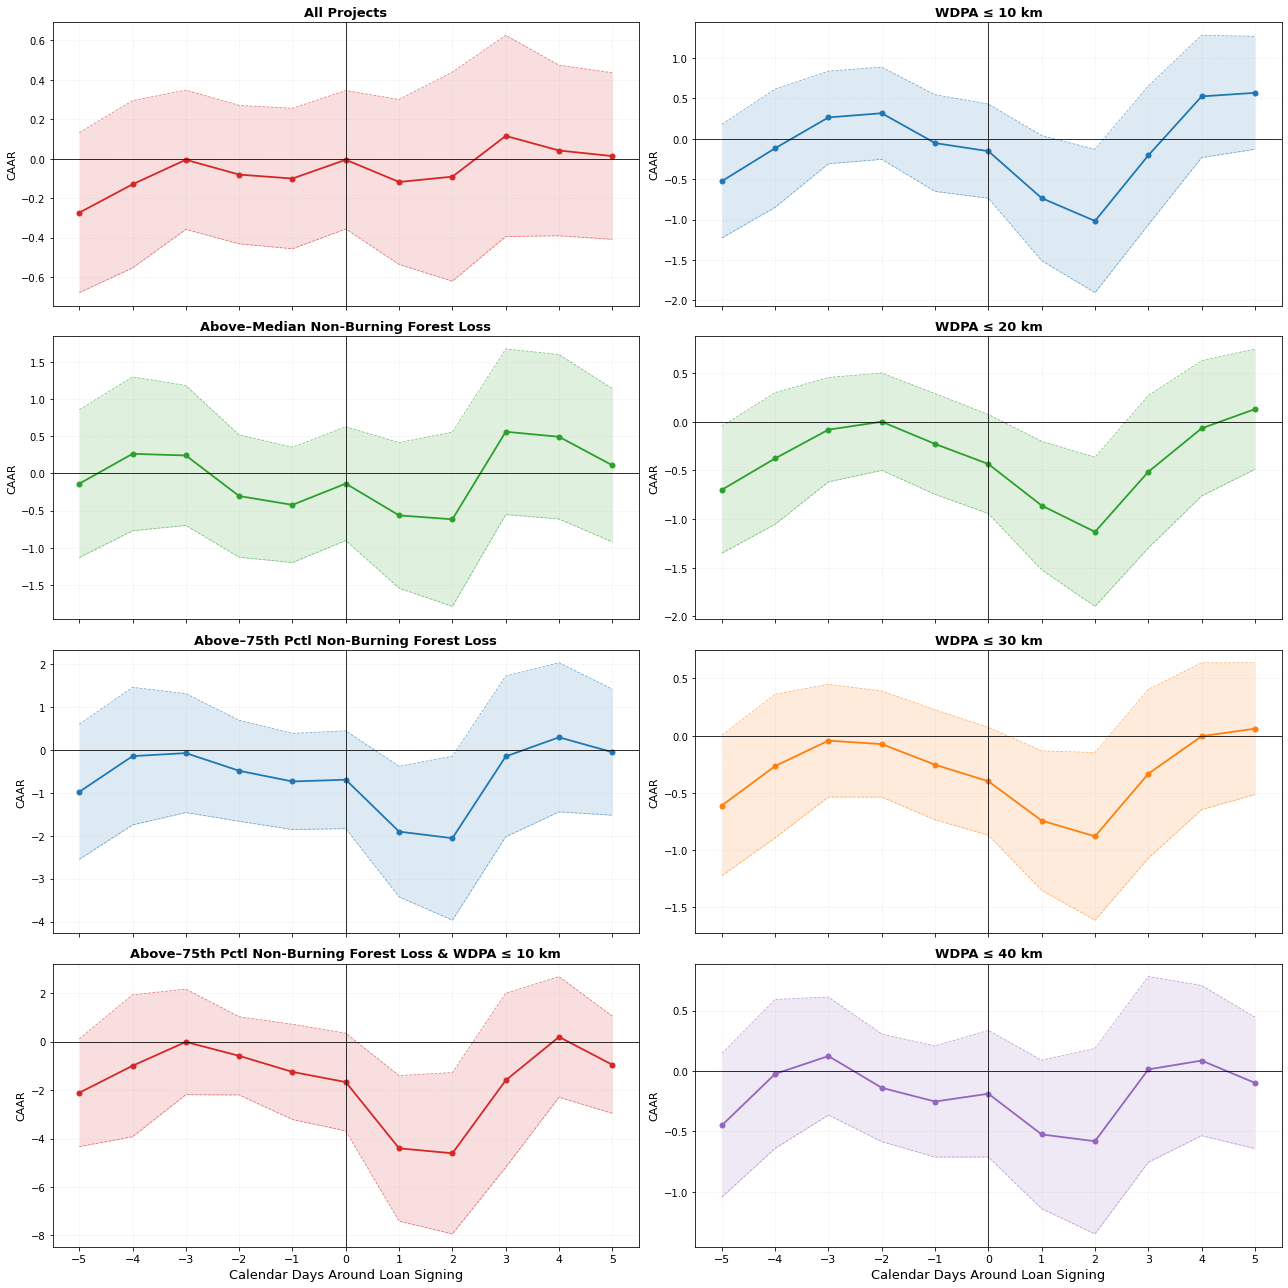

In [17]:
# ---------------------------------------------------------------- Fig. 5
layout = [
    ("All Projects", "tab:red"),
    ("WDPA ≤ 10 km", "tab:blue"),
    ("Above–Median Non-Burning Forest Loss", "tab:green"),
    ("WDPA ≤ 20 km", "tab:green"),
    ("Above–75th Pctl Non-Burning Forest Loss", "tab:blue"),
    ("WDPA ≤ 30 km", "tab:orange"),
    ("Above–75th Pctl Non-Burning Forest Loss & WDPA ≤ 10 km", "tab:red"),
    ("WDPA ≤ 40 km", "tab:purple"),
]

fig, axes = plt.subplots(4, 2, figsize=(18, 18), sharex=True)
for ax, (name, color) in zip(axes.flat, layout):
    t = tables[name]
    x = t["day"].to_numpy()
    mean = t["mean"].to_numpy()
    lower = t["lower"].to_numpy()
    upper = t["upper"].to_numpy()

    ax.fill_between(x, lower, upper, color=color, alpha=0.15, linewidth=0)
    ax.plot(x, lower, color=color, linestyle="--", linewidth=0.8, alpha=0.6)
    ax.plot(x, upper, color=color, linestyle="--", linewidth=0.8, alpha=0.6)
    ax.plot(x, mean, color=color, marker="o", markersize=5, linewidth=1.8)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(name, fontsize=13, fontweight="bold")
    ax.set_ylabel("CAAR", fontsize=11)
    ax.set_xticks(range(PLOT_WINDOW[0], PLOT_WINDOW[1] + 1))
    ax.grid(True, linestyle=":", linewidth=0.5, alpha=0.5)
for ax in axes[-1]:
    ax.set_xlabel("Calendar Days Around Loan Signing", fontsize=13)
    ax.tick_params(axis="x", labelsize=11)

fig.tight_layout()
fig.savefig(OUT_DIR / "figure5.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT_DIR / "figure5.pdf", bbox_inches="tight")
plt.show()